In [2]:
using PyPlot
using QuantumOptics
using LinearAlgebra

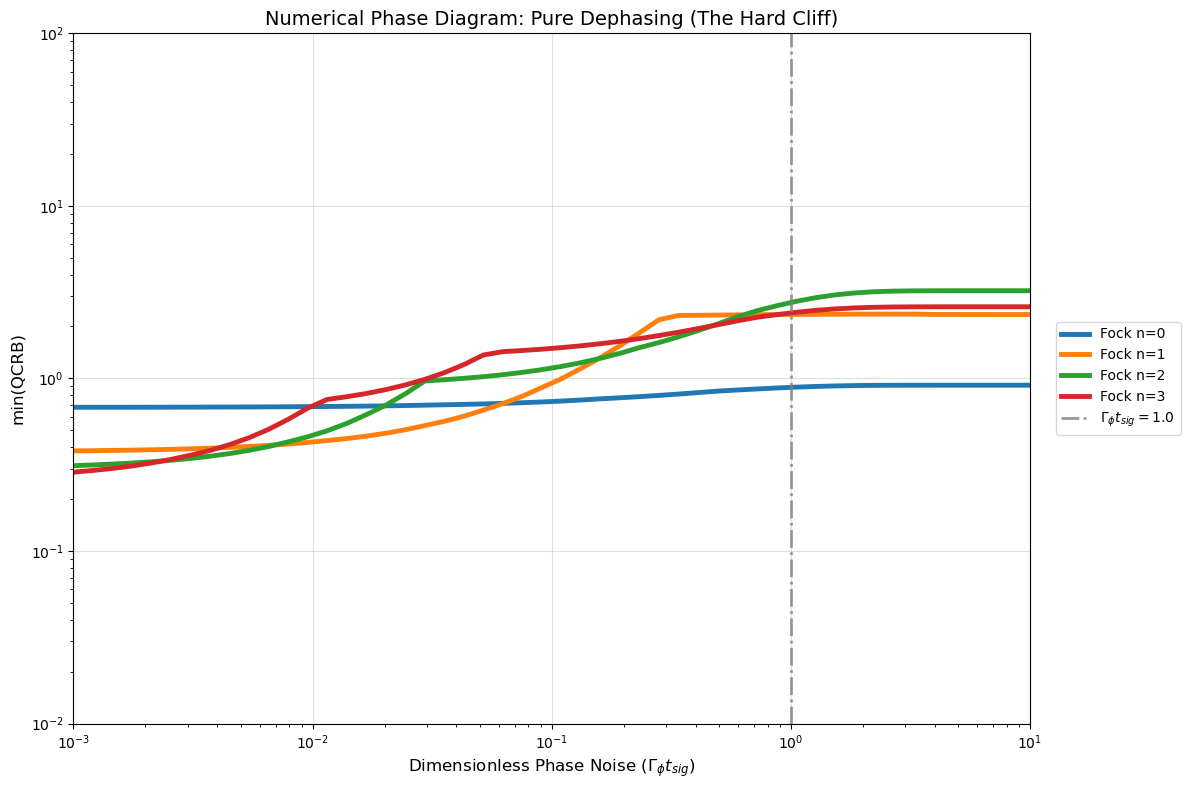

Simulating exact phase-space interferometry... (May take 10-20 seconds)


In [3]:


# -------------------------------------------------------------
# Exact Numerical Ancilla QCRB (Spin Overlap Protocol)
# -------------------------------------------------------------
function get_dephased_ancilla_qcrb(n_fock::Int, Gamma_t::Float64)
    # 1. Define Hilbert space large enough to prevent boundary clipping
    N_cut = 70 
    b = FockBasis(N_cut)
    
    # 2. Sweep the laser amplitude to find the optimal envelope
    alpha_sweep = range(0.05, stop=3.5, length=100)
    min_qcrb = Inf
    
    psi_initial = fockstate(b, n_fock)
    
    for alpha in alpha_sweep
        # Step A: Simulate the displaced wavepacket in one arm of the interferometer
        D_op = displace(b, alpha)
        rho = dm(D_op * psi_initial)
        
        # Step B: Apply Pure Dephasing to the motional mode
        # Dephasing kills off-diagonal elements exponentially by (n-m)^2
        for i in 1:N_cut
            for j in 1:N_cut
                n_i = i - 1
                n_j = j - 1
                rho.data[i, j] *= exp(-0.5 * Gamma_t * (n_i - n_j)^2)
            end
        end
        
        # Step C: Calculate the spin coherence overlap V = Tr(rho * D(-2alpha))
        V_op = displace(b, -2.0 * alpha)
        V_val = real(expect(V_op, rho))
        
        # Step D: Calculate Ancilla QCRB (Analogous to your Eq 74)
        if abs(V_val) > 1e-10
            # The denominator perfectly maps to the 16 * alpha^2 * V^2 scaling
            qcrb = 1.0 / (16.0 * alpha^2 * V_val^2)
            
            if qcrb < min_qcrb
                min_qcrb = qcrb
            end
        end
    end
    
    return min_qcrb
end

# -------------------------------------------------------------
# Pure Dephasing Phase Diagram Plotter
# -------------------------------------------------------------
function plot_numerical_dephasing_crossover()
    n_vals = [0, 1, 2, 3]
    
    # Dimensionless sweep from ultra-low noise to severe phase noise
    gamma_t_sweep = 10.0 .^ range(-3.0, 1.0, length=50)
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3")
    
    fig = figure(figsize=(12, 8))
    
    println("Simulating exact phase-space interferometry... (May take 10-20 seconds)")
    
    for n in n_vals
        qcrb_vals = Float64[]
        for gt in gamma_t_sweep
            push!(qcrb_vals, get_dephased_ancilla_qcrb(n, gt))
        end
        plot(gamma_t_sweep, qcrb_vals, color=state_colors[n], linewidth=3.5, label="Fock n=$n")
    end
    
    # Add Reference Line
    axvline(x=1.0, color="gray", linestyle="-.", linewidth=2.0, alpha=0.8, label=L"\Gamma_\phi t_{sig} = 1.0")
    
    xscale("log"); yscale("log")
    
    # Match the viewing window to your analytical plots
    xlim(1e-3, 1e1)
    ylim(1e-2, 1e2)
    
    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Numerical Phase Diagram: Pure Dephasing (The Hard Cliff)", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=10, loc="center left", bbox_to_anchor=(1.02, 0.5))
    tight_layout()
    
    display(fig)
    println("==================================================")
end

plot_numerical_dephasing_crossover()

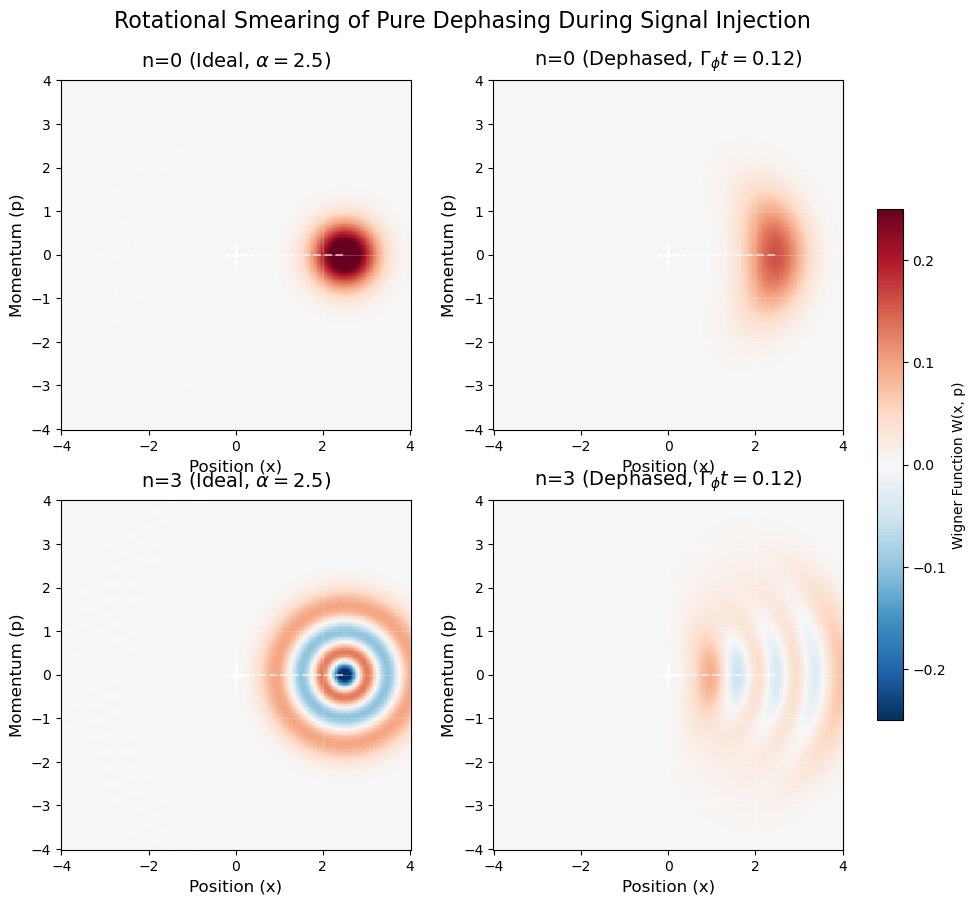

Calculating Wigner distributions...


In [4]:
using PyPlot
using QuantumOptics

function plot_corrected_wigner()
    N_cut = 60
    b = FockBasis(N_cut)
    
    alpha_val = 2.5
    Gamma_t = 0.12  # Mild phase noise

    # 1. Initialize bare states
    psi0 = fockstate(b, 0)
    psi3 = fockstate(b, 3)

    # 2. Apply initial laser displacement
    D_op = displace(b, alpha_val)
    rho0_ideal = dm(D_op * psi0)
    rho3_ideal = dm(D_op * psi3)

    rho0_dephased = deepcopy(rho0_ideal)
    rho3_dephased = deepcopy(rho3_ideal)

    # 3. Apply Pure Dephasing
    dim = length(b)
    for i in 1:dim
        for j in 1:dim
            n_i = i - 1
            n_j = j - 1
            decay_factor = exp(-0.5 * Gamma_t * (n_i - n_j)^2)
            rho0_dephased.data[i, j] *= decay_factor
            rho3_dephased.data[i, j] *= decay_factor
        end
    end

    # 4. Perfectly symmetric grid to match Re(alpha) and Im(alpha) [i.e., -4 to 4]
    grid_alpha = range(-4.0, stop=4.0, length=250)
    
    # Scale coordinates to match QuantumOptics.jl internal definition
    grid_qo = grid_alpha .* sqrt(2)

    println("Calculating Wigner distributions...")
    W0_id = wigner(rho0_ideal, grid_qo, grid_qo)
    W0_dp = wigner(rho0_dephased, grid_qo, grid_qo)
    W3_id = wigner(rho3_ideal, grid_qo, grid_qo)
    W3_dp = wigner(rho3_dephased, grid_qo, grid_qo)

    # 5. Plotting (Matches your reference image style)
    fig, axs = subplots(2, 2, figsize=(11, 10))

    function draw_panel(ax, W_data, title_str)
        # CRITICAL FIX: Transpose the matrix (W_data') to correct the Julia-to-Python coordinate flip
        c = ax.pcolormesh(grid_alpha, grid_alpha, W_data', cmap="RdBu_r", vmin=-0.25, vmax=0.25, shading="auto")
        
        ax.set_title(title_str, fontsize=14, pad=10)
        ax.set_aspect("equal")
        ax.set_xlabel("Position (x)", fontsize=12)
        ax.set_ylabel("Momentum (p)", fontsize=12)
        
        # Add faint white grid lines like the reference image
        ax.grid(true, color="white", alpha=0.3, linewidth=0.5)
        
        # Large white cross at the origin
        ax.plot(0, 0, "w+", markersize=16, markeredgewidth=2)
        
        # Dashed line showing the pure displacement strictly along the x-axis
        ax.plot([0, alpha_val], [0, 0], "w--", alpha=0.6, linewidth=1.5)
        
        return c
    end

    draw_panel(axs[1,1], W0_id, L"n=0 (Ideal, $\alpha=2.5$)")
    draw_panel(axs[1,2], W0_dp, L"n=0 (Dephased, $\Gamma_\phi t=0.12$)")
    
    draw_panel(axs[2,1], W3_id, L"n=3 (Ideal, $\alpha=2.5$)")
    c = draw_panel(axs[2,2], W3_dp, L"n=3 (Dephased, $\Gamma_\phi t=0.12$)")

    fig.colorbar(c, ax=vec(axs), orientation="vertical", fraction=0.03, pad=0.04, label="Wigner Function W(x, p)")
    
    suptitle("Rotational Smearing of Pure Dephasing During Signal Injection", fontsize=16, y=0.95)
    
    display(fig)
end

plot_corrected_wigner()

 EXECUTING EXACT NUMERICAL SOLVER & CROSSOVER SEARCH
Crossover n=2 -> n=1:
  Dimensionless (Γ_ϕ * t_sig) : 0.00701
  Physical Dephasing (Γ_ϕ)    : 3.18 Hz
  QCRB Value                  : 0.4117
----------------------------------------------------------
Crossover n=1 -> n=0:
  Dimensionless (Γ_ϕ * t_sig) : 0.06293
  Physical Dephasing (Γ_ϕ)    : 28.52 Hz
  QCRB Value                  : 0.717
----------------------------------------------------------


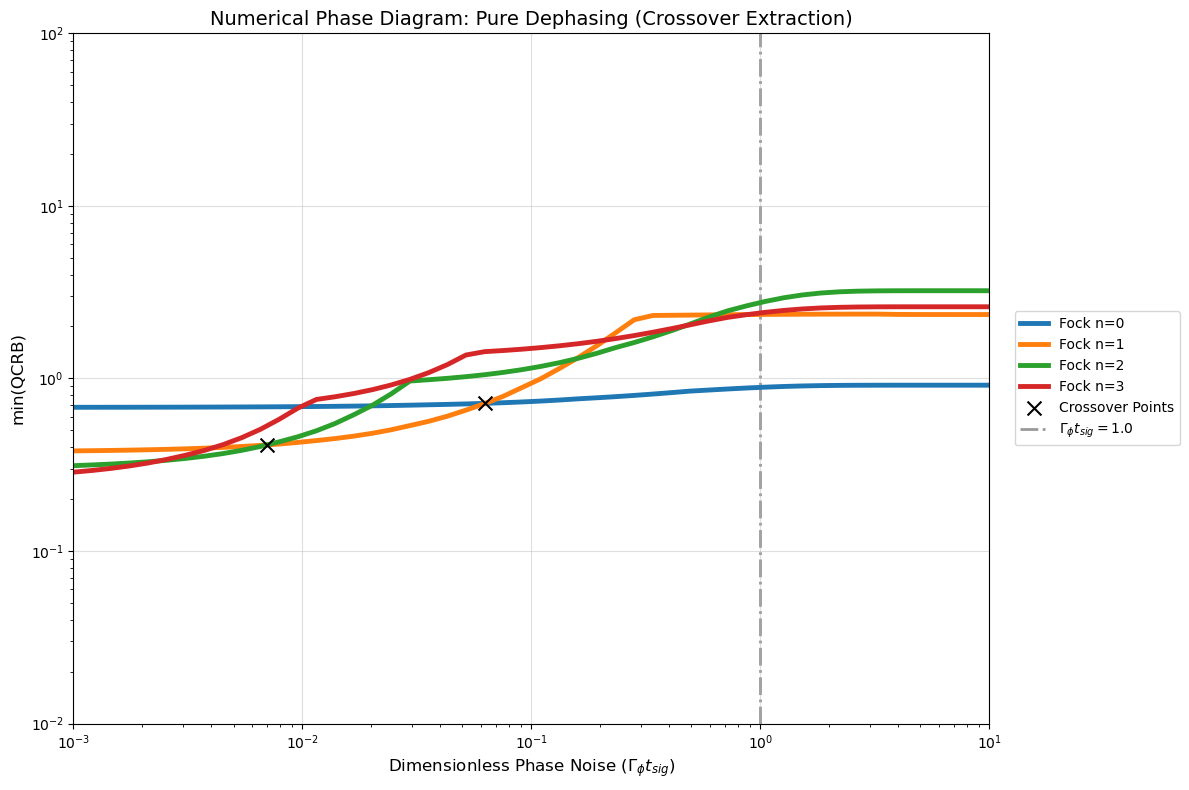

In [7]:
using PyPlot
using QuantumOptics

# -------------------------------------------------------------
# Exact Numerical Ancilla QCRB (Spin Overlap Protocol)
# -------------------------------------------------------------
function get_dephased_ancilla_qcrb(n_fock::Int, Gamma_t::Float64)
    N_cut = 70 
    b = FockBasis(N_cut)
    
    alpha_sweep = range(0.05, stop=3.5, length=100)
    min_qcrb = Inf
    
    psi_initial = fockstate(b, n_fock)
    
    for alpha in alpha_sweep
        # Step A: Simulate the displaced wavepacket
        D_op = displace(b, alpha)
        rho = dm(D_op * psi_initial)
        
        # Step B: Apply Pure Dephasing to the motional mode
        for i in 1:N_cut
            for j in 1:N_cut
                n_i = i - 1
                n_j = j - 1
                rho.data[i, j] *= exp(-0.5 * Gamma_t * (n_i - n_j)^2)
            end
        end
        
        # Step C: Calculate the spin coherence overlap
        V_op = displace(b, -2.0 * alpha)
        V_val = real(expect(V_op, rho))
        
        # Step D: Calculate Ancilla QCRB
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
            end
        end
    end
    return min_qcrb
end

# -------------------------------------------------------------
# Logarithmic Bisection Root Finder
# -------------------------------------------------------------
function find_crossover(n1::Int, n2::Int, g_min::Float64, g_max::Float64; tol=1e-4)
    # Objective function: difference in QCRB between the two states
    f(g) = get_dephased_ancilla_qcrb(n1, g) - get_dephased_ancilla_qcrb(n2, g)
    
    val_min = f(g_min)
    val_max = f(g_max)
    
    # If the curves don't cross in this range, return NaN
    if sign(val_min) == sign(val_max)
        return NaN, NaN
    end
    
    g_mid = g_min
    val_mid = 0.0
    
    # Logarithmic bisection for heavily scaled phase space
    for _ in 1:40
        log_mid = (log10(g_min) + log10(g_max)) / 2.0
        g_mid = 10.0^log_mid
        val_mid = f(g_mid)
        
        if abs(val_mid) < tol || abs(g_max - g_min) < tol
            break
        end
        
        if sign(val_mid) == sign(val_min)
            g_min = g_mid
            val_min = val_mid
        else
            g_max = g_mid
            val_max = val_mid
        end
    end
    
    qcrb_at_cross = get_dephased_ancilla_qcrb(n1, g_mid)
    return g_mid, qcrb_at_cross
end

# -------------------------------------------------------------
# Pure Dephasing Phase Diagram & Crossover Plotter
# -------------------------------------------------------------
function plot_numerical_dephasing_crossover()
    n_vals = [0, 1, 2, 3]
    
    # Dimensionless sweep
    g_min_sweep = 1e-3
    g_max_sweep = 1e1
    gamma_t_sweep = 10.0 .^ range(log10(g_min_sweep), log10(g_max_sweep), length=50)
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3")
    
    # From previous notebook logs: beta=1.0 resulted in t_sig = 2206.67 us
    t_sig_s = 0.00220667 
    
    fig = figure(figsize=(12, 8))
    println("==========================================================")
    println(" EXECUTING EXACT NUMERICAL SOLVER & CROSSOVER SEARCH")
    println("==========================================================")
    
    # 1. Plot the standard curves
    for n in n_vals
        qcrb_vals = Float64[]
        for gt in gamma_t_sweep
            push!(qcrb_vals, get_dephased_ancilla_qcrb(n, gt))
        end
        plot(gamma_t_sweep, qcrb_vals, color=state_colors[n], linewidth=3.5, label="Fock n=$n", zorder=2)
    end
    
    # 2. Find and scatter the exact crossovers
    crossovers_to_find = [(3, 2), (2, 1), (1, 0)]
    cross_pts_x = Float64[]
    cross_pts_y = Float64[]
    
    for (nA, nB) in crossovers_to_find
        g_cross, qcrb_cross = find_crossover(nA, nB, g_min_sweep, g_max_sweep)
        
        if !isnan(g_cross)
            push!(cross_pts_x, g_cross)
            push!(cross_pts_y, qcrb_cross)
            
            # Calculate physical Gamma in Hz
            gamma_hz = g_cross / t_sig_s
            
            println("Crossover n=$nA -> n=$nB:")
            println("  Dimensionless (Γ_ϕ * t_sig) : ", round(g_cross, digits=5))
            println("  Physical Dephasing (Γ_ϕ)    : ", round(gamma_hz, digits=2), " Hz")
            println("  QCRB Value                  : ", round(qcrb_cross, digits=4))
            println("----------------------------------------------------------")
        end
    end
    
    # Plot intersection markers
    scatter(cross_pts_x, cross_pts_y, color="black", s=100, zorder=5, marker="x", label="Crossover Points")
    
    # Add Reference Line
    axvline(x=1.0, color="gray", linestyle="-.", linewidth=2.0, alpha=0.8, label=L"\Gamma_\phi t_{sig} = 1.0", zorder=1)
    
    xscale("log"); yscale("log")
    xlim(g_min_sweep, g_max_sweep)
    ylim(1e-2, 1e2)
    
    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Numerical Phase Diagram: Pure Dephasing (Crossover Extraction)", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=10, loc="center left", bbox_to_anchor=(1.02, 0.5))
    tight_layout()
    
    display(fig)
    println("==========================================================")
end

plot_numerical_dephasing_crossover()

Tracking optimal control parameters for n=3... (May take 10-20 seconds)

 INTERNAL INFLECTION POINTS DETECTED (n=3)
Inflection Point 1:
  Noise Threshold (Γ_ϕ t_sig) : 0.0111
  QCRB Discontinuity          : 0.7481
  Optimal α Snapped Inward    : From 1.55 -> 1.0
--------------------------------------------------
Inflection Point 2:
  Noise Threshold (Γ_ϕ t_sig) : 0.0556
  QCRB Discontinuity          : 1.408
  Optimal α Snapped Inward    : From 0.97 -> 0.55
--------------------------------------------------


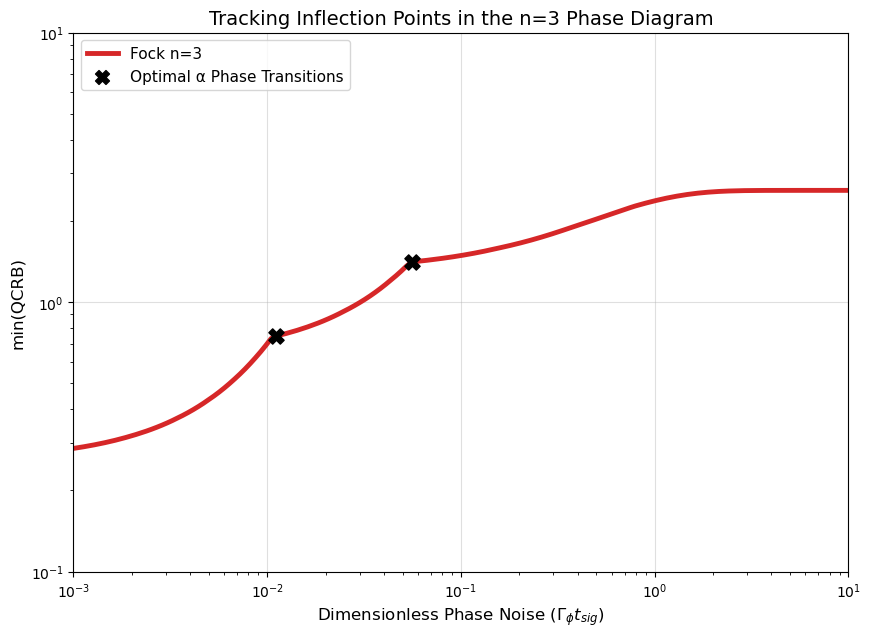

In [8]:
using PyPlot
using QuantumOptics

# -------------------------------------------------------------
# Solver: Returns both min(QCRB) and the Optimal Alpha used
# -------------------------------------------------------------
function get_qcrb_and_opt_alpha(n_fock::Int, Gamma_t::Float64)
    N_cut = 70 
    b = FockBasis(N_cut)
    
    # High resolution alpha sweep to cleanly track the valleys
    alpha_sweep = range(0.05, stop=3.0, length=250)
    min_qcrb = Inf
    opt_alpha = 0.0
    
    psi_initial = fockstate(b, n_fock)
    
    for alpha in alpha_sweep
        D_op = displace(b, alpha)
        rho = dm(D_op * psi_initial)
        
        # Apply Pure Dephasing 
        for i in 1:N_cut
            for j in 1:N_cut
                rho.data[i, j] *= exp(-0.5 * Gamma_t * (i - j)^2)
            end
        end
        
        V_val = real(expect(displace(b, -2.0 * alpha), rho))
        
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
                opt_alpha = alpha
            end
        end
    end
    
    return min_qcrb, opt_alpha
end

# -------------------------------------------------------------
# Phase Diagram Kink Finder
# -------------------------------------------------------------
function extract_internal_inflections(n_fock::Int)
    gamma_t_sweep = 10.0 .^ range(-3.0, 1.0, length=150)
    
    qcrbs = Float64[]
    opt_alphas = Float64[]
    
    println("Tracking optimal control parameters for n=$n_fock... (May take 10-20 seconds)")
    
    for gt in gamma_t_sweep
        q, a = get_qcrb_and_opt_alpha(n_fock, gt)
        push!(qcrbs, q)
        push!(opt_alphas, a)
    end
    
    kink_gammas = Float64[]
    kink_qcrbs = Float64[]
    kink_alpha_jumps = []
    
    # Detect discontinuous "snaps" in the optimal alpha
    for i in 2:length(opt_alphas)
        # If the optimal alpha jumps inward by a large amount (crossing a Laguerre root)
        if (opt_alphas[i-1] - opt_alphas[i]) > 0.15
            push!(kink_gammas, gamma_t_sweep[i])
            push!(kink_qcrbs, qcrbs[i])
            push!(kink_alpha_jumps, (opt_alphas[i-1], opt_alphas[i]))
        end
    end
    
    # --- Plotting ---
    fig = figure(figsize=(10, 7))
    
    plot(gamma_t_sweep, qcrbs, color="C3", linewidth=3.5, label="Fock n=$n_fock")
    
    println("\n==================================================")
    println(" INTERNAL INFLECTION POINTS DETECTED (n=$n_fock)")
    println("==================================================")
    
    for (idx, (g_val, q_val, a_jump)) in enumerate(zip(kink_gammas, kink_qcrbs, kink_alpha_jumps))
        scatter([g_val], [q_val], color="black", s=120, zorder=5, marker="X")
        
        println("Inflection Point $idx:")
        println("  Noise Threshold (Γ_ϕ t_sig) : ", round(g_val, digits=4))
        println("  QCRB Discontinuity          : ", round(q_val, digits=4))
        println("  Optimal α Snapped Inward    : From $(round(a_jump[1], digits=2)) -> $(round(a_jump[2], digits=2))")
        println("--------------------------------------------------")
    end
    
    # Add fake scatter for legend
    scatter([], [], color="black", s=100, marker="X", label="Optimal α Phase Transitions")
    
    xscale("log"); yscale("log")
    xlim(1e-3, 1e1); ylim(1e-1, 1e1)
    
    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Tracking Inflection Points in the n=$n_fock Phase Diagram", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=11, loc="upper left")
    
    display(fig)
end

# Extract the 3 kinks for n=3
extract_internal_inflections(3)

In [ ]:
extract_internal_inflections(2)

 TRACKING OPTIMAL CONTROL TRANSITIONS (n=3)
 Laser Intensity (I) : 1000.0
 Coupling Rate (g)   : 453.17 rad/s
 Exposure Time (t)   : 2206.67 μs

Simulating exact phase-space interferometry... (May take 10-20 seconds)
Inflection Point (Kink) 1:
  Dimensionless (Γ_ϕ t_sig) : 0.0111
  Physical Dephasing (Γ_ϕ)  : 5.03 Hz
  Optimal α Snapped Inward  : From 1.54 -> 1.0
--------------------------------------------------
Inflection Point (Kink) 2:
  Dimensionless (Γ_ϕ t_sig) : 0.0561
  Physical Dephasing (Γ_ϕ)  : 25.41 Hz
  Optimal α Snapped Inward  : From 0.97 -> 0.55
--------------------------------------------------


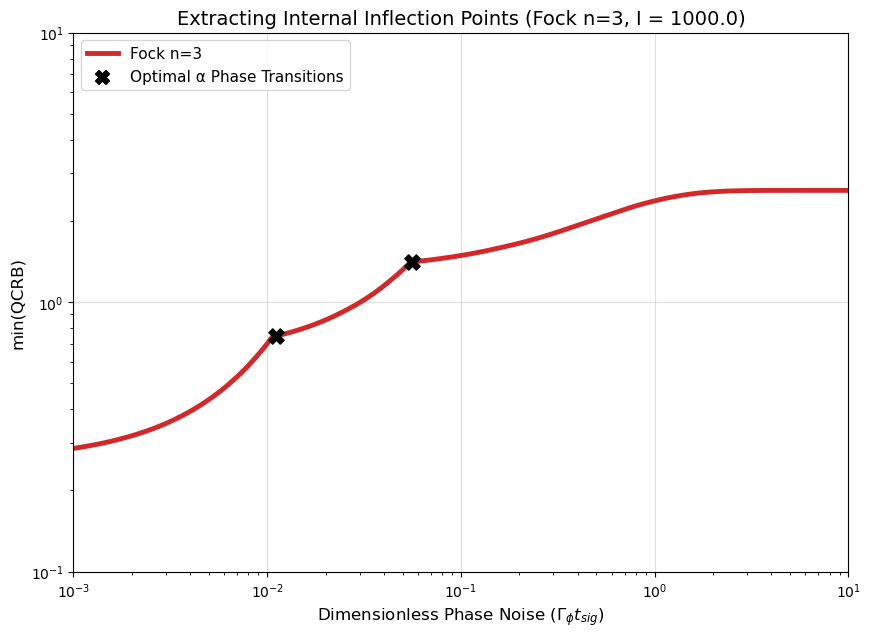

In [9]:
using PyPlot
using QuantumOptics
using IonSim

# -------------------------------------------------------------
# Solver: Returns both min(QCRB) and the Optimal Alpha used
# -------------------------------------------------------------
function get_qcrb_and_opt_alpha(n_fock::Int, Gamma_t::Float64)
    N_cut = 70 
    b = FockBasis(N_cut)
    
    # High resolution alpha sweep to cleanly track the valleys
    alpha_sweep = range(0.05, stop=3.0, length=250)
    min_qcrb = Inf
    opt_alpha = 0.0
    
    psi_initial = fockstate(b, n_fock)
    
    for alpha in alpha_sweep
        D_op = displace(b, alpha)
        rho = dm(D_op * psi_initial)
        
        # Apply Pure Dephasing 
        for i in 1:N_cut
            for j in 1:N_cut
                rho.data[i, j] *= exp(-0.5 * Gamma_t * (i - j)^2)
            end
        end
        
        V_val = real(expect(displace(b, -2.0 * alpha), rho))
        
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
                opt_alpha = alpha
            end
        end
    end
    
    return min_qcrb, opt_alpha
end

# -------------------------------------------------------------
# Phase Diagram Kink Finder & Physical Translator
# -------------------------------------------------------------
function extract_internal_inflections(n_fock::Int=3, laser_intensity::Float64=1e3)
    # 1. Calculate physical t_sig dynamically based on the laser intensity
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_total = 2 * π / transition_λ
    k_z = k_total / sqrt(2)
    eta = k_z * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    Omega_eff = Omega_eff_Hz * 2 * π
    
    beta_signal = 1.0
    t_sig_s = (2 * beta_signal) / (eta * Omega_eff)
    t_sig_us = t_sig_s * 1e6
    g_display = round((eta * Omega_eff_Hz * 2 * π) / 2.0, digits=2)

    # 2. Sweep the phase diagram
    gamma_t_sweep = 10.0 .^ range(-3.0, 1.0, length=200) # Increased resolution for sharp kink detection
    
    qcrbs = Float64[]
    opt_alphas = Float64[]
    
    println("==================================================")
    println(" TRACKING OPTIMAL CONTROL TRANSITIONS (n=$n_fock)")
    println("==================================================")
    println(" Laser Intensity (I) : ", laser_intensity)
    println(" Coupling Rate (g)   : ", g_display, " rad/s")
    println(" Exposure Time (t)   : ", round(t_sig_us, digits=2), " μs")
    println("==================================================\n")
    println("Simulating exact phase-space interferometry... (May take 10-20 seconds)")
    
    for gt in gamma_t_sweep
        q, a = get_qcrb_and_opt_alpha(n_fock, gt)
        push!(qcrbs, q)
        push!(opt_alphas, a)
    end
    
    kink_gammas = Float64[]
    kink_qcrbs = Float64[]
    kink_alpha_jumps = []
    
    # 3. Detect discontinuous "snaps" in the optimal alpha
    for i in 2:length(opt_alphas)
        if (opt_alphas[i-1] - opt_alphas[i]) > 0.15
            push!(kink_gammas, gamma_t_sweep[i])
            push!(kink_qcrbs, qcrbs[i])
            push!(kink_alpha_jumps, (opt_alphas[i-1], opt_alphas[i]))
        end
    end
    
    # 4. Plotting
    fig = figure(figsize=(10, 7))
    plot(gamma_t_sweep, qcrbs, color="C3", linewidth=3.5, label="Fock n=$n_fock")
    
    for (idx, (g_val, q_val, a_jump)) in enumerate(zip(kink_gammas, kink_qcrbs, kink_alpha_jumps))
        scatter([g_val], [q_val], color="black", s=120, zorder=5, marker="X")
        
        # Translate to physical Hz
        gamma_hz = g_val / t_sig_s
        
        println("Inflection Point (Kink) $idx:")
        println("  Dimensionless (Γ_ϕ t_sig) : ", round(g_val, digits=4))
        println("  Physical Dephasing (Γ_ϕ)  : ", round(gamma_hz, digits=2), " Hz")
        println("  Optimal α Snapped Inward  : From $(round(a_jump[1], digits=2)) -> $(round(a_jump[2], digits=2))")
        println("--------------------------------------------------")
    end
    
    scatter([], [], color="black", s=100, marker="X", label="Optimal α Phase Transitions")
    
    xscale("log"); yscale("log")
    xlim(1e-3, 1e1); ylim(1e-1, 1e1)
    
    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Extracting Internal Inflection Points (Fock n=$n_fock, I = $laser_intensity)", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=11, loc="upper left")
    
    display(fig)
end

# Run the extraction for n=3 using I = 1000 W/m^2
extract_internal_inflections(3, 1e3)

 TRACKING OPTIMAL CONTROL TRANSITIONS (n=2)
 Laser Intensity (I) : 1000.0
 Coupling Rate (g)   : 453.17 rad/s
 Exposure Time (t)   : 2206.67 μs

Simulating exact phase-space interferometry... (May take 10-20 seconds)
Inflection Point (Kink) 1:
  Dimensionless (Γ_ϕ t_sig) : 0.0293
  Physical Dephasing (Γ_ϕ)  : 13.29 Hz
  Optimal α Snapped Inward  : From 1.22 -> 0.67
--------------------------------------------------


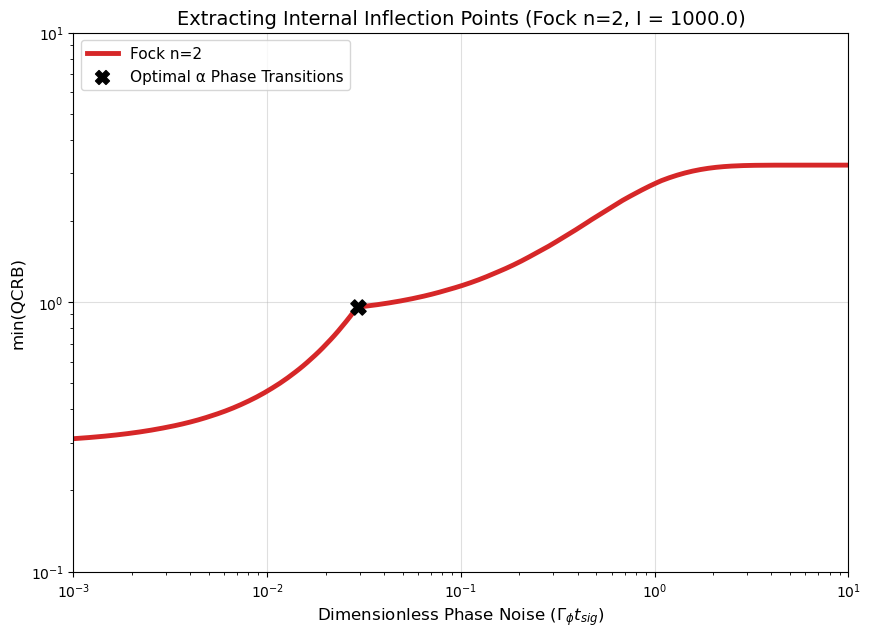

In [11]:
extract_internal_inflections(2, 1e3)

 TRACKING OPTIMAL CONTROL TRANSITIONS (n=2)
 Laser Intensity (I) : 100000.0
 Coupling Rate (g)   : 4531.71 rad/s
 Exposure Time (t)   : 220.67 μs

Simulating exact phase-space interferometry... (May take 10-20 seconds)
Inflection Point (Kink) 1:
  Dimensionless (Γ_ϕ t_sig) : 0.0293
  Physical Dephasing (Γ_ϕ)  : 132.92 Hz
  Optimal α Snapped Inward  : From 1.22 -> 0.67
--------------------------------------------------


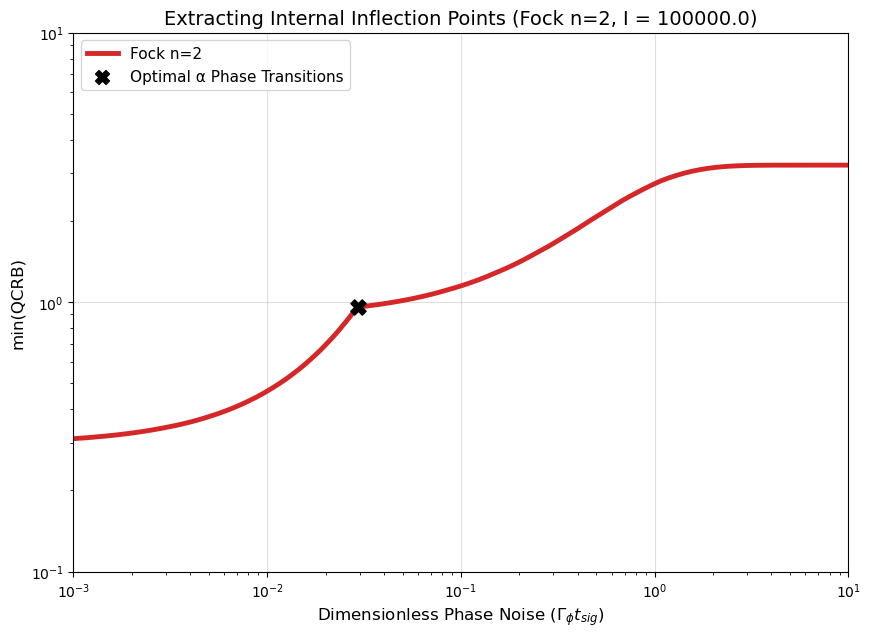

In [12]:
extract_internal_inflections(2, 1e5)

 EXECUTING EXACT NUMERICAL SOLVER & CROSSOVER SEARCH
Crossover n=2 -> n=1:
  Dimensionless (Γ_ϕ * t_sig) : 0.00701
  Physical Dephasing (Γ_ϕ)    : 3.18 Hz
  QCRB Value                  : 0.4117
----------------------------------------------------------
Crossover n=1 -> n=0:
  Dimensionless (Γ_ϕ * t_sig) : 0.06293
  Physical Dephasing (Γ_ϕ)    : 28.52 Hz
  QCRB Value                  : 0.717
----------------------------------------------------------


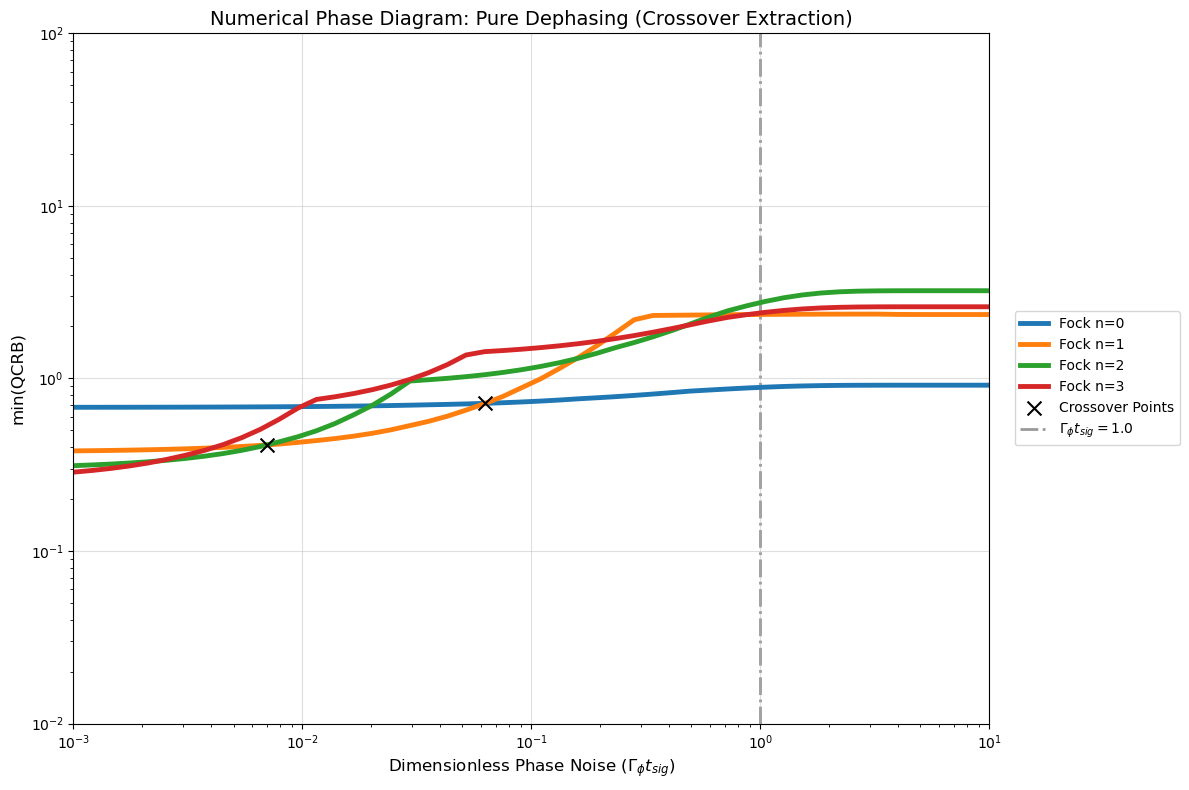

In [ ]:
using PyPlot
using QuantumOptics

# -------------------------------------------------------------
# Exact Numerical Ancilla QCRB (Spin Overlap Protocol)
# -------------------------------------------------------------
function get_dephased_ancilla_qcrb(n_fock::Int, Gamma_t::Float64)
    N_cut = 70 
    b = FockBasis(N_cut)
    
    alpha_sweep = range(0.05, stop=3.5, length=100)
    min_qcrb = Inf
    
    psi_initial = fockstate(b, n_fock)
    
    for alpha in alpha_sweep
        # Step A: Simulate the displaced wavepacket
        D_op = displace(b, alpha)
        rho = dm(D_op * psi_initial)
        
        # Step B: Apply Pure Dephasing to the motional mode
        for i in 1:N_cut
            for j in 1:N_cut
                n_i = i - 1
                n_j = j - 1
                rho.data[i, j] *= exp(-0.5 * Gamma_t * (n_i - n_j)^2)
            end
        end
        
        # Step C: Calculate the spin coherence overlap
        V_op = displace(b, 2.0 * alpha)
        V_val = real(expect(V_op, rho))
        
        # Step D: Calculate Ancilla QCRB
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
            end
        end
    end

    
    return min_qcrb
end

# -------------------------------------------------------------
# Logarithmic Bisection Root Finder
# -------------------------------------------------------------
function find_crossover(n1::Int, n2::Int, g_min::Float64, g_max::Float64; tol=1e-4)
    # Objective function: difference in QCRB between the two states
    f(g) = get_dephased_ancilla_qcrb(n1, g) - get_dephased_ancilla_qcrb(n2, g)
    
    val_min = f(g_min)
    val_max = f(g_max)
    
    # If the curves don't cross in this range, return NaN
    if sign(val_min) == sign(val_max)
        return NaN, NaN
    end
    
    g_mid = g_min
    val_mid = 0.0
    
    # Logarithmic bisection for heavily scaled phase space
    for _ in 1:40
        log_mid = (log10(g_min) + log10(g_max)) / 2.0
        g_mid = 10.0^log_mid
        val_mid = f(g_mid)
        
        if abs(val_mid) < tol || abs(g_max - g_min) < tol
            break
        end
        
        if sign(val_mid) == sign(val_min)
            g_min = g_mid
            val_min = val_mid
        else
            g_max = g_mid
            val_max = val_mid
        end
    end
    
    qcrb_at_cross = get_dephased_ancilla_qcrb(n1, g_mid)
    return g_mid, qcrb_at_cross
end

# -------------------------------------------------------------
# Pure Dephasing Phase Diagram & Crossover Plotter
# -------------------------------------------------------------
function plot_numerical_dephasing_crossover()
    n_vals = [0, 1, 2, 3]
    
    # Dimensionless sweep
    g_min_sweep = 1e-3
    g_max_sweep = 1e1
    gamma_t_sweep = 10.0 .^ range(log10(g_min_sweep), log10(g_max_sweep), length=50)
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3")
    
    # From previous notebook logs: beta=1.0 resulted in t_sig = 2206.67 us
    t_sig_s = 0.00220667 
    
    fig = figure(figsize=(12, 8))
    println("==========================================================")
    println(" EXECUTING EXACT NUMERICAL SOLVER & CROSSOVER SEARCH")
    println("==========================================================")
    
    # 1. Plot the standard curves
    for n in n_vals
        qcrb_vals = Float64[]
        for gt in gamma_t_sweep
            push!(qcrb_vals, get_dephased_ancilla_qcrb(n, gt))
        end
        plot(gamma_t_sweep, qcrb_vals, color=state_colors[n], linewidth=3.5, label="Fock n=$n", zorder=2)
    end
    
    # 2. Find and scatter the exact crossovers
    crossovers_to_find = [(3, 2), (2, 1), (1, 0)]
    cross_pts_x = Float64[]
    cross_pts_y = Float64[]
    
    for (nA, nB) in crossovers_to_find
        g_cross, qcrb_cross = find_crossover(nA, nB, g_min_sweep, g_max_sweep)
        
        if !isnan(g_cross)
            push!(cross_pts_x, g_cross)
            push!(cross_pts_y, qcrb_cross)
            
            # Calculate physical Gamma in Hz
            gamma_hz = g_cross / t_sig_s
            
            println("Crossover n=$nA -> n=$nB:")
            println("  Dimensionless (Γ_ϕ * t_sig) : ", round(g_cross, digits=5))
            println("  Physical Dephasing (Γ_ϕ)    : ", round(gamma_hz, digits=2), " Hz")
            println("  QCRB Value                  : ", round(qcrb_cross, digits=4))
            println("----------------------------------------------------------")
        end
    end
    
    # Plot intersection markers
    scatter(cross_pts_x, cross_pts_y, color="black", s=100, zorder=5, marker="x", label="Crossover Points")
    
    # Add Reference Line
    axvline(x=1.0, color="gray", linestyle="-.", linewidth=2.0, alpha=0.8, label=L"\Gamma_\phi t_{sig} = 1.0", zorder=1)
    
    xscale("log"); yscale("log")
    xlim(g_min_sweep, g_max_sweep)
    ylim(1e-2, 1e2)
    
    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Numerical Phase Diagram: Pure Dephasing (Crossover Extraction)", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=10, loc="center left", bbox_to_anchor=(1.02, 0.5))
    tight_layout()
    
    display(fig)
    println("==========================================================")
end

plot_numerical_dephasing_crossover()

 EXECUTING EXACT NUMERICAL SOLVER & CROSSOVER SEARCH
Crossover n=2 -> n=1:
  Dimensionless (Γ_ϕ * t_sig) : 0.00701
  Physical Dephasing (Γ_ϕ)    : 3.18 Hz
  QCRB Value                  : 0.4132
----------------------------------------------------------
Crossover n=1 -> n=0:
  Dimensionless (Γ_ϕ * t_sig) : 0.06293
  Physical Dephasing (Γ_ϕ)    : 28.52 Hz
  QCRB Value                  : 0.7399
----------------------------------------------------------


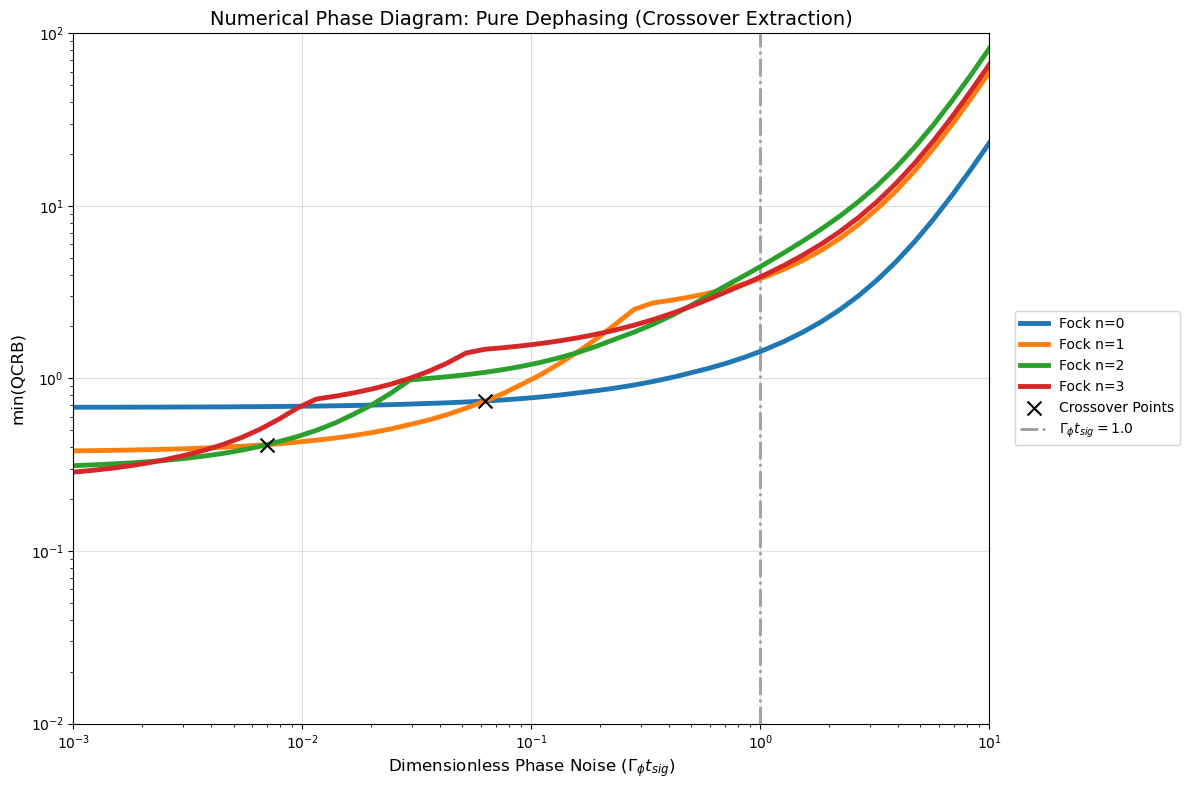

In [1]:
using PyPlot
using QuantumOptics

# -------------------------------------------------------------
# Exact Numerical Ancilla QCRB (Spin Overlap Protocol)
# -------------------------------------------------------------
function get_dephased_ancilla_qcrb(n_fock::Int, Gamma_t::Float64)
    N_cut = 70 
    b = FockBasis(N_cut)
        continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    alpha_sweep = range(0.05, stop=3.5, length=100)
    min_qcrb = Inf
    
    psi_initial = fockstate(b, n_fock)
    
    for alpha in alpha_sweep
        # Step A: Simulate the displaced wavepacket
        D_op = displace(b, alpha)
        rho = dm(D_op * psi_initial)
        
        # Step B: Apply Pure Dephasing to the motional mode
        for i in 1:N_cut
            for j in 1:N_cut
                n_i = i - 1
                n_j = j - 1
                rho.data[i, j] *= exp(-0.5 * Gamma_t * (n_i - n_j)^2)
            end
        end
        
        # Step C: Calculate the spin coherence overlap
        V_op = displace(b, 2.0 * alpha)
        V_val = real(expect(V_op, rho))
        
        # Step D: Calculate Ancilla QCRB
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * V_val^2)
            qcrb = qcrb / (continuous_signal_factor^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
            end
        end
    end

    
    return min_qcrb
end

# -------------------------------------------------------------
# Logarithmic Bisection Root Finder
# -------------------------------------------------------------
function find_crossover(n1::Int, n2::Int, g_min::Float64, g_max::Float64; tol=1e-4)
    # Objective function: difference in QCRB between the two states
    f(g) = get_dephased_ancilla_qcrb(n1, g) - get_dephased_ancilla_qcrb(n2, g)
    
    val_min = f(g_min)
    val_max = f(g_max)
    
    # If the curves don't cross in this range, return NaN
    if sign(val_min) == sign(val_max)
        return NaN, NaN
    end
    
    g_mid = g_min
    val_mid = 0.0
    
    # Logarithmic bisection for heavily scaled phase space
    for _ in 1:40
        log_mid = (log10(g_min) + log10(g_max)) / 2.0
        g_mid = 10.0^log_mid
        val_mid = f(g_mid)
        
        if abs(val_mid) < tol || abs(g_max - g_min) < tol
            break
        end
        
        if sign(val_mid) == sign(val_min)
            g_min = g_mid
            val_min = val_mid
        else
            g_max = g_mid
            val_max = val_mid
        end
    end
    
    qcrb_at_cross = get_dephased_ancilla_qcrb(n1, g_mid)
    return g_mid, qcrb_at_cross
end

# -------------------------------------------------------------
# Pure Dephasing Phase Diagram & Crossover Plotter
# -------------------------------------------------------------
function plot_numerical_dephasing_crossover()
    n_vals = [0, 1, 2, 3]
    
    # Dimensionless sweep
    g_min_sweep = 1e-3
    g_max_sweep = 1e1
    gamma_t_sweep = 10.0 .^ range(log10(g_min_sweep), log10(g_max_sweep), length=50)
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3")
    
    # From previous notebook logs: beta=1.0 resulted in t_sig = 2206.67 us
    t_sig_s = 0.00220667 
    
    fig = figure(figsize=(12, 8))
    println("==========================================================")
    println(" EXECUTING EXACT NUMERICAL SOLVER & CROSSOVER SEARCH")
    println("==========================================================")
    
    # 1. Plot the standard curves
    for n in n_vals
        qcrb_vals = Float64[]
        for gt in gamma_t_sweep
            push!(qcrb_vals, get_dephased_ancilla_qcrb(n, gt))
        end
        plot(gamma_t_sweep, qcrb_vals, color=state_colors[n], linewidth=3.5, label="Fock n=$n", zorder=2)
    end
    
    # 2. Find and scatter the exact crossovers
    crossovers_to_find = [(3, 2), (2, 1), (1, 0)]
    cross_pts_x = Float64[]
    cross_pts_y = Float64[]
    
    for (nA, nB) in crossovers_to_find
        g_cross, qcrb_cross = find_crossover(nA, nB, g_min_sweep, g_max_sweep)
        
        if !isnan(g_cross)
            push!(cross_pts_x, g_cross)
            push!(cross_pts_y, qcrb_cross)
            
            # Calculate physical Gamma in Hz
            gamma_hz = g_cross / t_sig_s
            
            println("Crossover n=$nA -> n=$nB:")
            println("  Dimensionless (Γ_ϕ * t_sig) : ", round(g_cross, digits=5))
            println("  Physical Dephasing (Γ_ϕ)    : ", round(gamma_hz, digits=2), " Hz")
            println("  QCRB Value                  : ", round(qcrb_cross, digits=4))
            println("----------------------------------------------------------")
        end
    end
    
    # Plot intersection markers
    scatter(cross_pts_x, cross_pts_y, color="black", s=100, zorder=5, marker="x", label="Crossover Points")
    
    # Add Reference Line
    axvline(x=1.0, color="gray", linestyle="-.", linewidth=2.0, alpha=0.8, label=L"\Gamma_\phi t_{sig} = 1.0", zorder=1)
    
    xscale("log"); yscale("log")
    xlim(g_min_sweep, g_max_sweep)
    ylim(1e-2, 1e2)
    
    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Numerical Phase Diagram: Pure Dephasing (Crossover Extraction)", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=10, loc="center left", bbox_to_anchor=(1.02, 0.5))
    tight_layout()
    
    display(fig)
    println("==========================================================")
end

plot_numerical_dephasing_crossover()

In [2]:
extract_internal_inflections(3, 1e3)

UndefVarError: UndefVarError: `extract_internal_inflections` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

Tracking optimal control parameters for n=3... (May take 10-20 seconds)

 INTERNAL INFLECTION POINTS DETECTED (n=3)
Inflection Point 1:
  Noise Threshold (Γ_ϕ t_sig) : 0.0111
  QCRB Discontinuity          : 0.7523
  Optimal α Snapped Inward    : From 1.55 -> 1.0
--------------------------------------------------
Inflection Point 2:
  Noise Threshold (Γ_ϕ t_sig) : 0.0556
  QCRB Discontinuity          : 1.4476
  Optimal α Snapped Inward    : From 0.97 -> 0.55
--------------------------------------------------


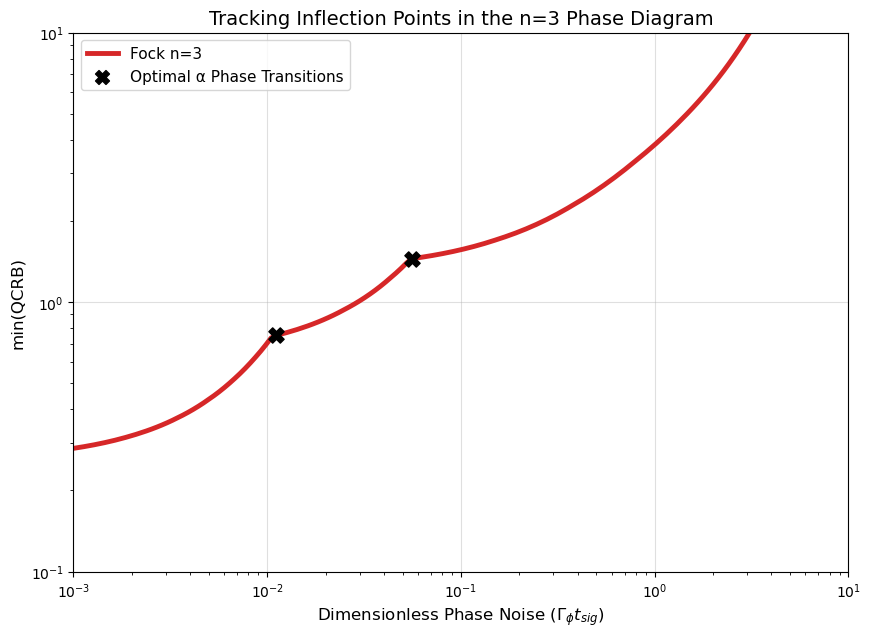

In [3]:
using PyPlot
using QuantumOptics

# -------------------------------------------------------------
# Solver: Returns both min(QCRB) and the Optimal Alpha used
# -------------------------------------------------------------
function get_qcrb_and_opt_alpha(n_fock::Int, Gamma_t::Float64)
    N_cut = 70 
    b = FockBasis(N_cut)
    
    # High resolution alpha sweep to cleanly track the valleys
    alpha_sweep = range(0.05, stop=3.0, length=250)
    min_qcrb = Inf
    opt_alpha = 0.0
    
    psi_initial = fockstate(b, n_fock)
            continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    
    for alpha in alpha_sweep
        D_op = displace(b, alpha)
        rho = dm(D_op * psi_initial)
        
        # Apply Pure Dephasing 
        for i in 1:N_cut
            for j in 1:N_cut
                rho.data[i, j] *= exp(-0.5 * Gamma_t * (i - j)^2)
            end
        end
        
        V_val = real(expect(displace(b, -2.0 * alpha), rho))
        
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * V_val^2)
            qcrb = qcrb / (continuous_signal_factor^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
                opt_alpha = alpha
            end
        end
    end
    
    return min_qcrb, opt_alpha
end

# -------------------------------------------------------------
# Phase Diagram Kink Finder
# -------------------------------------------------------------
function extract_internal_inflections(n_fock::Int)
    gamma_t_sweep = 10.0 .^ range(-3.0, 1.0, length=150)
    
    qcrbs = Float64[]
    opt_alphas = Float64[]
    
    println("Tracking optimal control parameters for n=$n_fock... (May take 10-20 seconds)")
    
    for gt in gamma_t_sweep
        q, a = get_qcrb_and_opt_alpha(n_fock, gt)
        push!(qcrbs, q)
        push!(opt_alphas, a)
    end
    
    kink_gammas = Float64[]
    kink_qcrbs = Float64[]
    kink_alpha_jumps = []
    
    # Detect discontinuous "snaps" in the optimal alpha
    for i in 2:length(opt_alphas)
        # If the optimal alpha jumps inward by a large amount (crossing a Laguerre root)
        if (opt_alphas[i-1] - opt_alphas[i]) > 0.15
            push!(kink_gammas, gamma_t_sweep[i])
            push!(kink_qcrbs, qcrbs[i])
            push!(kink_alpha_jumps, (opt_alphas[i-1], opt_alphas[i]))
        end
    end
    
    # --- Plotting ---
    fig = figure(figsize=(10, 7))
    
    plot(gamma_t_sweep, qcrbs, color="C3", linewidth=3.5, label="Fock n=$n_fock")
    
    println("\n==================================================")
    println(" INTERNAL INFLECTION POINTS DETECTED (n=$n_fock)")
    println("==================================================")
    
    for (idx, (g_val, q_val, a_jump)) in enumerate(zip(kink_gammas, kink_qcrbs, kink_alpha_jumps))
        scatter([g_val], [q_val], color="black", s=120, zorder=5, marker="X")
        
        println("Inflection Point $idx:")
        println("  Noise Threshold (Γ_ϕ t_sig) : ", round(g_val, digits=4))
        println("  QCRB Discontinuity          : ", round(q_val, digits=4))
        println("  Optimal α Snapped Inward    : From $(round(a_jump[1], digits=2)) -> $(round(a_jump[2], digits=2))")
        println("--------------------------------------------------")
    end
    
    # Add fake scatter for legend
    scatter([], [], color="black", s=100, marker="X", label="Optimal α Phase Transitions")
    
    xscale("log"); yscale("log")
    xlim(1e-3, 1e1); ylim(1e-1, 1e1)
    
    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Tracking Inflection Points in the n=$n_fock Phase Diagram", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=11, loc="upper left")
    
    display(fig)
end

# Extract the 3 kinks for n=3
extract_internal_inflections(3)